## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [5]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")

os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [6]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


## 3. Configuration

#### this is sample configuration, you are free to modify any parameter to train the best performing model

In [7]:
import os
import random
import json
import time
import math
import zipfile
import shutil

# Hugging Face dataset
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"

# You can use any of the 4 train files or all the files for pre-training the legal model
TRAIN_FILES = ["Phase_1_Pretraining/Train/train_supreme_court.json"]
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

# Training configuration
TRAIN_TOKENS = 50_000_000
VAL_TOKENS = 5_000_000
TRAIN_BLOCK_SIZE = 2048
EPOCHS = 1
SEED = 42
random.seed(SEED)
MODEL_CONTEXT_LENGTH = 2048
N_EMBD = 768
N_LAYER = 12
N_HEAD = 12

# Generation
TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 384
TEMPERATURE = 0.1
TOP_P = 0.95

# Kaggle output
OUTPUT_DIR = "/content/cs781_phase1"
MODEL_OUTPUT_DIR = os.path.join(
    OUTPUT_DIR,
    "legal-gpt2-final"
)
PREDICTION_PATH = os.path.join(
    OUTPUT_DIR,
    "prediction.json"
)
SUBMISSION_ZIP = os.path.join(
    OUTPUT_DIR,
    "submission.zip"
)
LOSS_PLOT_PATH = os.path.join(
    OUTPUT_DIR,
    "training_validation_loss.png"
)
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)
print("Configuration loaded.")

Configuration loaded.


## 4. Load Tokenizer

In [8]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")
tokenizer.pad_token = tokenizer.eos_token

#to avoid corrupt batching we are mannually setting padding side to be left
tokenizer.padding_side = "left"

print("Vocabulary size:", len(tokenizer))

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Vocabulary size: 50257


## 5. Download Training Data From Hugging Face

In [9]:
# from huggingface_hub import hf_hub_download

# train_file_paths = []
# print("Downlading the training files")

# for file_name in TRAIN_FILES:
#     file_path = hf_hub_download(
#         repo_id=HF_DATASET_REPO,
#         filename=file_name,
#         repo_type="dataset",
#         token=HF_TOKEN
#     )
#     train_file_paths.append(file_path)
#     print(f"Ready: {file_name}")

## 6. Create Train and Validation Tokens Set

In [10]:
# train_tokens = []
# val_tokens = []
# all_records = []

# # 1. Load all records from all downloaded files
# for path in train_file_paths:
#     with open(path, "r", encoding="utf-8") as f:
#         all_records.extend(json.load(f))

# print(f"Total documents loaded: {len(all_records):,}")

# # 2. Shuffle to mix the legal texts evenly
# random.seed(SEED)
# random.shuffle(all_records)

# # 3. Define the End-of-Sequence token
# eos_id = [tokenizer.eos_token_id]

# # 4. Tokenize and distribute to train/val sets
# for data in all_records:
#     text = data["text"]

#     # Crucial Fix: Append EOS token to the end of each document
#     tokens = tokenizer.encode(text, add_special_tokens=False) + eos_id

#     if random.random() < 0.05:
#         if len(val_tokens) < VAL_TOKENS:
#             remaining = VAL_TOKENS - len(val_tokens)
#             val_tokens.extend(tokens[:remaining])
#     else:
#         if len(train_tokens) < TRAIN_TOKENS:
#             remaining = TRAIN_TOKENS - len(train_tokens)
#             train_tokens.extend(tokens[:remaining])

#     if len(train_tokens) >= TRAIN_TOKENS and len(val_tokens) >= VAL_TOKENS:
#         break

# print(f"Train tokens: {len(train_tokens):,}")
# print(f"Validation tokens: {len(val_tokens):,}")

In [11]:
#to avoid the crashing RAM we are not downloading dataset manually

from datasets import load_dataset

print("Loading Dataset from HuggingFace")
#Loading the datsets using Hugging Face's Arrow Backend to make it memory efficient
raw_dataset = load_dataset(
    HF_DATASET_REPO,
    data_files=TRAIN_FILES,
    split="train",
    streaming = "True",
    token=HF_TOKEN
)

#Shuffling the dataset on disk
raw_dataset = raw_dataset.shuffle(seed=SEED)

train_tokens = []
val_tokens = []
eos_id = [tokenizer.eos_token_id]

#Processing the dataset iteratively in a loop to avoid RAM spikes
for row in raw_dataset:
    text = row["text"]

    # Tokenize and append the End-Of-Sequence separator
    tokens = tokenizer.encode(text, add_special_tokens=False) + eos_id

    # Distribute tokens to validation and training sets
    if random.random() < 0.05:
        if len(val_tokens) < VAL_TOKENS:
            remaining = VAL_TOKENS - len(val_tokens)
            val_tokens.extend(tokens[:remaining])
    else:
        if len(train_tokens) < TRAIN_TOKENS:
            remaining = TRAIN_TOKENS - len(train_tokens)
            train_tokens.extend(tokens[:remaining])

    # Stop processing once both budgets are filled
    if len(train_tokens) >= TRAIN_TOKENS and len(val_tokens) >= VAL_TOKENS:
        break

print(f"Train tokens: {len(train_tokens):,}")
print(f"Validation tokens: {len(val_tokens):,}")

Loading Dataset from HuggingFace


README.md:   0%|          | 0.00/16.1k [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (3227 > 1024). Running this sequence through the model will result in indexing errors


Train tokens: 50,000,000
Validation tokens: 5,000,000


## 7. Create Token Blocks

In [12]:
# def create_blocks(tokens, block_size):
#     total_length = (len(tokens) // block_size) * block_size
#     tokens = tokens[:total_length]
#     return [tokens[i:i + block_size] for i in range(0, total_length, block_size)]

# train_blocks = create_blocks(train_tokens, TRAIN_BLOCK_SIZE)
# val_blocks = create_blocks(val_tokens, TRAIN_BLOCK_SIZE)

# print("Training sequences:", len(train_blocks))
# print("Validation sequences:", len(val_blocks))

In [13]:
import gc

def create_blocks(tokens, block_size):
    total_length = (len(tokens) // block_size) * block_size
    tokens = tokens[:total_length]
    return [tokens[i:i + block_size] for i in range(0, total_length, block_size)]

train_blocks = create_blocks(train_tokens, TRAIN_BLOCK_SIZE)
val_blocks = create_blocks(val_tokens, TRAIN_BLOCK_SIZE)

print("Training sequences:", len(train_blocks))
print("Validation sequences:", len(val_blocks))

# CRITICAL: Free up system RAM by deleting the 1D token lists
del train_tokens
del val_tokens
gc.collect()

Training sequences: 24414
Validation sequences: 2441


158

## 8. Create Datasets

In [14]:
# from datasets import Dataset

# train_dataset = Dataset.from_dict({"input_ids": train_blocks})
# val_dataset = Dataset.from_dict({"input_ids": val_blocks})

# print(train_dataset)
# print(val_dataset)

In [15]:
from datasets import Dataset

train_dataset = Dataset.from_dict({"input_ids": train_blocks})
val_dataset = Dataset.from_dict({"input_ids": val_blocks})

print(train_dataset)
print(val_dataset)

# CRITICAL: Free up system RAM by deleting the 2D block lists
del train_blocks
del val_blocks
gc.collect()

Dataset({
    features: ['input_ids'],
    num_rows: 24414
})
Dataset({
    features: ['input_ids'],
    num_rows: 2441
})


72

## 9. Define The Model

In [16]:
from transformers import GPT2Config, GPT2LMHeadModel, DataCollatorForLanguageModeling

# Scaled-down architecture tuned for ~55M parameters
config = GPT2Config(
    vocab_size=len(tokenizer),
    n_positions=MODEL_CONTEXT_LENGTH,
    n_ctx=MODEL_CONTEXT_LENGTH,
    n_embd=512,               # Reduced embedding width (baseline is 768)
    n_layer=8,                # 8 layers
    n_head=8,                 # 8 heads (512 / 8 = 64 dimension per head)
    bos_token_id=tokenizer.bos_token_id,
    eos_token_id=tokenizer.eos_token_id,
    pad_token_id=tokenizer.eos_token_id
)

# Instantiate from scratch (random weights)
model = GPT2LMHeadModel(config)

model_size = sum(p.numel() for p in model.parameters())
print(f"Minimal Scaled-Down Model size: {model_size / 1e6:.2f}M parameters")

# Standard causal language modeling collator
data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

Minimal Scaled-Down Model size: 52.00M parameters


## 10. Training Arguments

In [17]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir=MODEL_OUTPUT_DIR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=8,
    learning_rate=3e-4,
    weight_decay=0.1,
    warmup_steps=500,
    lr_scheduler_type="cosine",
    fp16=torch.cuda.is_available(),
    eval_strategy="steps",
    eval_steps=1000,
    logging_steps=100,
    save_steps=1000,
    save_total_limit=2,
    seed=SEED,
    report_to="none",
    dataloader_num_workers=2,
    gradient_checkpointing=True
    #logging_dir=os.path.join(OUTPUT_DIR, "logs")
)

## 11. Training

In [18]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    processing_class=tokenizer
)

start_time = time.time()

trainer.train()

training_time = (time.time() - start_time)

tokens_per_epoch = (len(train_dataset) * TRAIN_BLOCK_SIZE)

total_tokens = (tokens_per_epoch * EPOCHS)

tokens_per_second = (total_tokens / training_time)

print(f"Training time: {training_time / 3600:.2f} hours")
print(f"Training speed: {tokens_per_second:,.0f} tokens/sec")

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.
[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Step,Training Loss,Validation Loss
1000,4.275802,4.189423
1526,3.973888,3.930288


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training time: 1.49 hours
Training speed: 9,343 tokens/sec


## 12. Perplexity

In [19]:
eval_results = trainer.evaluate()
eval_loss = eval_results["eval_loss"]
perplexity = math.exp(eval_loss)
print(f"Validation loss: {eval_loss:.6f}")
print(f"Validation perplexity: {perplexity:.4f}")

Training Loss,Validation Loss,Step
3.973888,3.930288,1526


Validation loss: 3.930288
Validation perplexity: 50.9216


## 13. Plot Training and Validation Loss

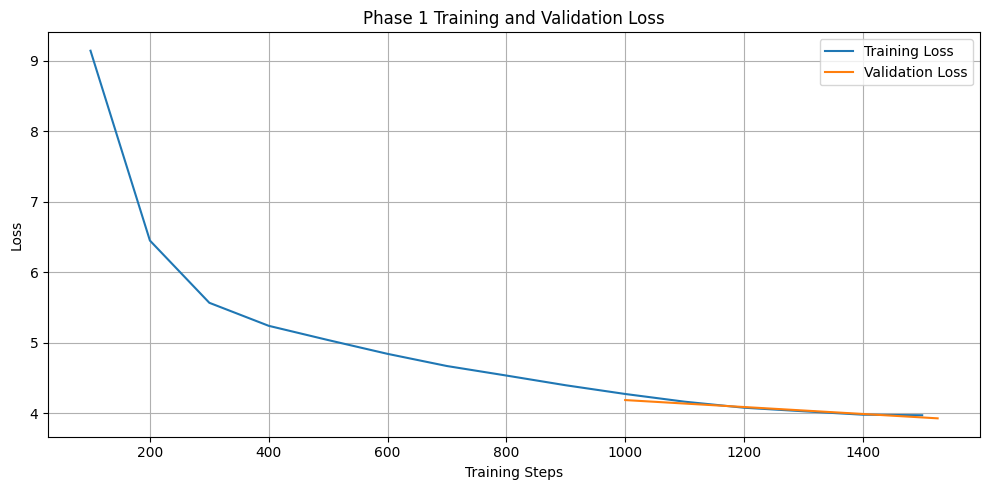

Loss plot saved to:
/content/cs781_phase1/training_validation_loss.png


In [20]:
import matplotlib.pyplot as plt

logs = trainer.state.log_history

train_steps = []
train_loss = []
eval_steps = []
eval_loss = []

for log in logs:
    if ("loss" in log and "step" in log):
        train_steps.append(log["step"])
        train_loss.append(log["loss"])
    if ("eval_loss" in log and "step" in log):
        eval_steps.append(log["step"])
        eval_loss.append(log["eval_loss"])

plt.figure(figsize=(10, 5))
plt.plot(train_steps, train_loss, label="Training Loss")
plt.plot(eval_steps, eval_loss, label="Validation Loss")
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Phase 1 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

print("Loss plot saved to:")
print(LOSS_PLOT_PATH)

## 14. Save Final Model to Kaggle Output

In [21]:
trainer.save_model(MODEL_OUTPUT_DIR)
tokenizer.save_pretrained(MODEL_OUTPUT_DIR)

print("Final model saved to:")
print(MODEL_OUTPUT_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Final model saved to:
/content/cs781_phase1/legal-gpt2-final


## 15. Push Model to Hugging Face Hub

In [22]:
# model.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)
# tokenizer.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)

# print("Model and tokenizer pushed successfully.")

## 16. Load Test Data from HuggingFace

In [24]:
from huggingface_hub import hf_hub_download
test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TEST_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)

print("Test file:", test_file_path)

test.json:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

Test file: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Test/test.json


## 17. Load Test Prompts

In [25]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

print("Number of test examples:", len(test_data))

Number of test examples: 1000


## 18. Load Final Model for Generation

In [26]:
from transformers import AutoTokenizer, GPT2LMHeadModel
import torch

generation_tokenizer = AutoTokenizer.from_pretrained(MODEL_OUTPUT_DIR)
generation_model = GPT2LMHeadModel.from_pretrained(MODEL_OUTPUT_DIR)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

generation_model = generation_model.to(device)
generation_model.eval()
generation_model.config.use_cache = True
generation_tokenizer.padding_side = "left"

print("Device:", device)
print(f"Parameters: {sum(p.numel() for p in generation_model.parameters()) / 1e6:.2f}M")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Device: cuda
Parameters: 52.00M


## 19. Generate 128 Words
#### (words, not tokens)

In [27]:
def generate_batch(prompts, model, tokenizer, device, target_words=128):
    inputs = tokenizer(
        prompts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=MODEL_CONTEXT_LENGTH - MAX_GENERATION_TOKENS
    )

    inputs = {key: value.to(device) for key, value in inputs.items()}
    input_lengths = inputs["attention_mask"].sum(dim=1)

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=MAX_GENERATION_TOKENS,
            do_sample=True,
            temperature=TEMPERATURE,
            top_p=TOP_P,
            pad_token_id=tokenizer.eos_token_id,
        )

    predictions = []
    for i in range(len(prompts)):
        generated_tokens = outputs[i, input_lengths[i]:]
        generated_text = tokenizer.decode(generated_tokens, skip_special_tokens=True)
        generated_words = generated_text.split()
        generated_words = generated_words[:target_words]
        predictions.append(" ".join(generated_words))

    return predictions

## 20. Generate Predictions for the Test Set

In [28]:
predictions = {}
GENERATION_BATCH_SIZE = 4 

items = list(test_data.items())
total_examples = len(items)
print(f"Total test examples: {total_examples}")

for start in range(0, total_examples, GENERATION_BATCH_SIZE):
    batch = items[start:start + GENERATION_BATCH_SIZE]
    batch_ids = [str(example_id) for example_id, _ in batch]
    batch_prompts = [record["text"] for _, record in batch]
    
    batch_predictions = generate_batch(
        prompts=batch_prompts,
        model=generation_model,
        tokenizer=generation_tokenizer,
        device=device,
        target_words=128
    )
    
    for example_id, prediction in zip(batch_ids, batch_predictions):
        predictions[example_id] = {"text": prediction}
        
    completed = start + len(batch)
    print(f"Completed {completed}/{total_examples} ({(completed / total_examples) * 100:.1f}%)")
    
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Total test examples: 1000
Completed 4/1000 (0.4%)
Completed 8/1000 (0.8%)
Completed 12/1000 (1.2%)
Completed 16/1000 (1.6%)
Completed 20/1000 (2.0%)
Completed 24/1000 (2.4%)
Completed 28/1000 (2.8%)
Completed 32/1000 (3.2%)
Completed 36/1000 (3.6%)
Completed 40/1000 (4.0%)
Completed 44/1000 (4.4%)
Completed 48/1000 (4.8%)
Completed 52/1000 (5.2%)
Completed 56/1000 (5.6%)
Completed 60/1000 (6.0%)
Completed 64/1000 (6.4%)
Completed 68/1000 (6.8%)
Completed 72/1000 (7.2%)
Completed 76/1000 (7.6%)
Completed 80/1000 (8.0%)
Completed 84/1000 (8.4%)
Completed 88/1000 (8.8%)
Completed 92/1000 (9.2%)
Completed 96/1000 (9.6%)
Completed 100/1000 (10.0%)
Completed 104/1000 (10.4%)
Completed 108/1000 (10.8%)
Completed 112/1000 (11.2%)
Completed 116/1000 (11.6%)
Completed 120/1000 (12.0%)
Completed 124/1000 (12.4%)
Completed 128/1000 (12.8%)
Completed 132/1000 (13.2%)
Completed 136/1000 (13.6%)
Completed 140/1000 (14.0%)
Completed 144/1000 (14.4%)
Completed 148/1000 (14.8%)
Completed 152/1000 (15.2%

## 21. Save prediction.json

In [29]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(
        predictions,
        f,
        ensure_ascii=False,
        indent=2
    )

print("prediction.json saved:")
print(PREDICTION_PATH)

prediction.json saved:
/content/cs781_phase1/prediction.json


## 22. Create CodaBench Submission ZIP

In [30]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")

print("Codabench submission created:")
print(SUBMISSION_ZIP)

Codabench submission created:
/content/cs781_phase1/submission.zip


In [31]:
import shutil
from IPython.display import FileLink

shutil.copy(SUBMISSION_ZIP, "submission.zip")

display(FileLink("submission.zip"))

/kaggle/working/submission.zip